# ChestScan AI — Notebook organisé et nettoyé

Ce notebook regroupe le pipeline en étapes claires : environnement, données, préparation, modèles, entraînement optionnel, évaluation et analyse des erreurs.

**Important :**
- Exécuter les cellules dans l'ordre.
- Les cellules d'entraînement sont séparées et identifiées comme optionnelles : ne les exécute pas si tu veux seulement analyser les modèles déjà enregistrés.
- Le jeu `test` sert à l'évaluation finale, pas à choisir le seuil ni à ajuster le modèle.
- Les prédictions sont pédagogiques et ne constituent pas un diagnostic médical.


## 1. Imports et configuration

Les paramètres communs sont définis une seule fois ici. Évite de redéfinir `DATASET_PATH`, `X_val`, `y_val` ou les noms de modèles dans plusieurs cellules.


In [25]:
#%pip install matplotlib pillow kagglehub scikit-learn pandas

In [26]:
# from pathlib import Path

# PROJECT_ROOT = Path.cwd()

# if PROJECT_ROOT.name == "notebooks":
#     PROJECT_ROOT = PROJECT_ROOT.parent

# MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"

# for path in sorted(MODEL_DIR.iterdir()):
#     print(f"{path.name} — {path.stat().st_size / (1024**2):.2f} MB")

In [27]:


# 1. Configurer les threads avant les imports scientifiques
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

# 2. Imports Python
from pathlib import Path
from collections import Counter
import gc
import platform
import shutil
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# 3. Configuration du projet
SEED = 42
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

tf.keras.utils.set_random_seed(SEED)

# 4. Limiter les threads TensorFlow
try:
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print("Les paramètres TensorFlow ont déjà été initialisés.")

# 5. Chemins absolus de la VM
PROJECT_ROOT = Path("/workspace/chestscan-ai-cnn")

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODELS_DIR = ARTIFACTS_DIR / "models"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
MLFLOW_DIR = ARTIFACTS_DIR / "mlflow"

# Créer les dossiers de sortie
for directory in [MODELS_DIR, REPORTS_DIR, MLFLOW_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# 6. Vérifier que le projet existe
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Projet introuvable : {PROJECT_ROOT}\n"
        "Vérifie le chemin réel du projet sur la VM."
    )

# 7. Informations sur l'environnement
print("=" * 60)
print("CHESTSCAN AI — ENVIRONNEMENT VAST.AI")
print("=" * 60)

print("Python :", sys.version.split()[0])
print("OS :", platform.platform())
print("CPU :", os.cpu_count())
print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

print("\nRacine du projet :", PROJECT_ROOT)
print("Modèles :", MODELS_DIR)
print("Rapports :", REPORTS_DIR)
print("MLflow :", MLFLOW_DIR)

print("\nModèles disponibles :")
for model_path in MODELS_DIR.glob("*.keras"):
    print(f"- {model_path.name} ({model_path.stat().st_size / (1024**2):.2f} MB)")

print("=" * 60)
print("Configuration terminée.")


CHESTSCAN AI — ENVIRONNEMENT VAST.AI
Python : 3.10.12
OS : Linux-5.15.0-194-generic-x86_64-with-glibc2.35
CPU : 64
NumPy : 2.1.3
Pandas : 2.3.3
TensorFlow : 2.19.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Racine du projet : /workspace/chestscan-ai-cnn
Modèles : /workspace/chestscan-ai-cnn/artifacts/models
Rapports : /workspace/chestscan-ai-cnn/artifacts/reports
MLflow : /workspace/chestscan-ai-cnn/artifacts/mlflow

Modèles disponibles :
Configuration terminée.


## 2. Télécharger et localiser le dataset

On recherche automatiquement le dossier qui contient les trois sous-dossiers `train`, `val` et `test`, chacun avec `NORMAL` et `PNEUMONIA`. Cela évite de dépendre d'une variable temporaire créée dans une boucle.


In [28]:

from pathlib import Path
import kagglehub

PROJECT_ROOT = Path("/workspace/chestscan-ai-cnn")
DATA_DIR = PROJECT_ROOT / "data"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
MODELS_DIR = ARTIFACTS_DIR / "models"

# Chemin attendu dans le cache KaggleHub
DATASET_PATH = Path(
    "/root/.cache/kagglehub/datasets/"
    "paultimothymooney/chest-xray-pneumonia/"
    "versions/2/chest_xray"
)

def is_valid_dataset(path: Path) -> bool:
    """Vérifie la présence des dossiers train, val et test."""
    required_splits = ["train", "val", "test"]
    required_classes = ["NORMAL", "PNEUMONIA"]

    return (
        path.is_dir()
        and all(
            (path / split / class_name).is_dir()
            for split in required_splits
            for class_name in required_classes
        )
    )

# Vérifier le dataset ; télécharger uniquement s'il est absent ou incomplet
if is_valid_dataset(DATASET_PATH):
    print("Dataset déjà présent dans le cache KaggleHub.")
else:
    print("Dataset absent ou incomplet. Téléchargement depuis KaggleHub...")

    downloaded_path = kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )

    downloaded_path = Path(downloaded_path)

    # KaggleHub peut retourner le dossier parent du dataset
    candidates = [
        downloaded_path,
        downloaded_path / "chest_xray",
        downloaded_path / "chest_xray" / "chest_xray",
    ]

    # Chercher le dossier contenant train/NORMAL et train/PNEUMONIA
    candidates.extend(
        p.parent for p in downloaded_path.rglob("train")
        if p.is_dir()
    )

    valid_paths = list(dict.fromkeys(
        p for p in candidates if is_valid_dataset(p)
    ))

    if not valid_paths:
        raise FileNotFoundError(
            "Le dataset a été téléchargé, mais sa structure "
            "train/val/test avec NORMAL et PNEUMONIA est introuvable."
        )

    DATASET_PATH = valid_paths[0]

# Vérification finale
print(f"\nChemin du dataset : {DATASET_PATH}")

for split in ["train", "val", "test"]:
    split_path = DATASET_PATH / split
    print(f"{split}: OK")

print("\nDataset prêt à être utilisé.")


Dataset déjà présent dans le cache KaggleHub.

Chemin du dataset : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray
train: OK
val: OK
test: OK

Dataset prêt à être utilisé.


## 3. Audit des fichiers et des images

Cette étape compte les images, repère les extensions non prises en charge et vérifie si les images sont lisibles. Elle n'altère ni ne supprime aucun fichier.


In [29]:

from collections import Counter
from pathlib import Path

import pandas as pd
from PIL import Image, UnidentifiedImageError

# Configuration
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
SPLITS = ["train", "val", "test"]

audit_rows = []

for split in SPLITS:
    for class_name in CLASS_NAMES:
        folder = DATASET_PATH / split / class_name

        if not folder.is_dir():
            print(f"[ABSENT] {folder}")
            continue

        # Trier les fichiers pour obtenir un audit reproductible
        all_files = sorted(
            p for p in folder.iterdir() if p.is_file()
        )

        valid_count = 0
        corrupted = []
        modes = Counter()
        sizes = Counter()
        unsupported = 0

        for i, file_path in enumerate(all_files, start=1):
            if file_path.suffix.lower() not in VALID_EXTENSIONS:
                unsupported += 1
                continue

            try:
                # verify() vérifie l'intégrité structurelle du fichier.
                # Il faut rouvrir l'image pour lire ses métadonnées.
                with Image.open(file_path) as img:
                    img.verify()

                with Image.open(file_path) as img:
                    img_size = img.size
                    img_mode = img.mode

                valid_count += 1
                modes[img_mode] += 1
                sizes[img_size] += 1

            except (
                UnidentifiedImageError,
                OSError,
                ValueError,
                SyntaxError,
            ):
                corrupted.append(file_path.name)

            if i % 500 == 0:
                print(
                    f"{split}/{class_name}: "
                    f"{i}/{len(all_files)} fichiers examinés"
                )

        audit_rows.append({
            "split": split,
            "class": class_name,
            "files": len(all_files),
            "valid_images": valid_count,
            "unsupported_extensions": unsupported,
            "corrupted_images": len(corrupted),
            "corrupted_examples": corrupted[:10],
            "modes": dict(modes),
            "common_sizes": sizes.most_common(3),
        })

        print(
            f"[TERMINÉ] {split}/{class_name}: "
            f"{valid_count} valides, "
            f"{len(corrupted)} corrompues, "
            f"{unsupported} extensions non prises en charge"
        )

# Résultats
audit_df = pd.DataFrame(audit_rows)

if audit_df.empty:
    print("Aucun dossier de données n'a pu être audité.")
else:
    display(audit_df)

    # Sauvegarder le rapport sur la VM
    report_path = REPORTS_DIR / "dataset_audit.csv"
    audit_df.to_csv(report_path, index=False)
    print(f"\nRapport enregistré : {report_path}")


train/NORMAL: 500/1341 fichiers examinés
train/NORMAL: 1000/1341 fichiers examinés
[TERMINÉ] train/NORMAL: 1341 valides, 0 corrompues, 0 extensions non prises en charge
train/PNEUMONIA: 500/3875 fichiers examinés
train/PNEUMONIA: 1000/3875 fichiers examinés
train/PNEUMONIA: 1500/3875 fichiers examinés
train/PNEUMONIA: 2000/3875 fichiers examinés
train/PNEUMONIA: 2500/3875 fichiers examinés
train/PNEUMONIA: 3000/3875 fichiers examinés
train/PNEUMONIA: 3500/3875 fichiers examinés
[TERMINÉ] train/PNEUMONIA: 3875 valides, 0 corrompues, 0 extensions non prises en charge
[TERMINÉ] val/NORMAL: 8 valides, 0 corrompues, 0 extensions non prises en charge
[TERMINÉ] val/PNEUMONIA: 8 valides, 0 corrompues, 0 extensions non prises en charge
[TERMINÉ] test/NORMAL: 234 valides, 0 corrompues, 0 extensions non prises en charge
[TERMINÉ] test/PNEUMONIA: 390 valides, 0 corrompues, 0 extensions non prises en charge


,split,class,files,valid_images,unsupported_extensions,corrupted_images,corrupted_examples,modes,common_sizes
0,train,NORMAL,1341,1341,0,0,[],{'L': 1341},"[((1472, 1171), 2), ((1480, 1228), 2), ((1364,..."
1,train,PNEUMONIA,3875,3875,0,0,[],"{'L': 3592, 'RGB': 283}","[((1072, 648), 7), ((1080, 728), 6), ((1008, 6..."
2,val,NORMAL,8,8,0,0,[],{'L': 8},"[((1776, 1416), 1), ((1272, 1040), 1), ((1736,..."
3,val,PNEUMONIA,8,8,0,0,[],{'L': 8},"[((968, 592), 1), ((1072, 712), 1), ((1152, 66..."
4,test,NORMAL,234,234,0,0,[],{'L': 234},"[((2517, 1979), 2), ((1304, 952), 2), ((1168, ..."
5,test,PNEUMONIA,390,390,0,0,[],{'L': 390},"[((1112, 736), 3), ((952, 624), 2), ((952, 640..."



Rapport enregistré : /workspace/chestscan-ai-cnn/artifacts/reports/dataset_audit.csv


## 4. Construire les datasets TensorFlow

Les images sont converties en RGB, redimensionnées à `180×180` et gardées dans l'intervalle `[0, 255]`. C'est compatible avec le modèle MobileNetV2 actuel, qui contient déjà ses propres couches `Resizing(224, 224)` et `preprocess_input`.

Le dataset n'est pas mélangé pour `val` et `test`, afin que les labels restent dans le même ordre que les prédictions.


In [30]:

from pathlib import Path

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder: Path) -> list[Path]:
    """Retourne les chemins des images prises en charge dans un dossier."""
    folder = Path(folder)

    if not folder.exists():
        raise FileNotFoundError(
            f"Le dossier n'existe pas : {folder}"
        )

    if not folder.is_dir():
        raise NotADirectoryError(
            f"Le chemin n'est pas un dossier : {folder}"
        )

    return sorted(
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in VALID_EXTENSIONS
    )


In [31]:

from pathlib import Path
from collections import Counter

import numpy as np
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split

# ============================================================
# 1. Configuration du projet
# ============================================================

PROJECT_ROOT = Path("/workspace/chestscan-ai-cnn")
DATA_DIR = PROJECT_ROOT / "data"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
MODELS_DIR = ARTIFACTS_DIR / "models"

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Vérifier et télécharger le dataset si nécessaire
# ============================================================

EXPECTED_PATH = Path(
    "/root/.cache/kagglehub/datasets/"
    "paultimothymooney/chest-xray-pneumonia/"
    "versions/2/chest_xray"
)


def is_valid_dataset(path: Path) -> bool:
    """Vérifie la présence des trois splits et des deux classes."""
    return path.is_dir() and all(
        (path / split / class_name).is_dir()
        for split in ["train", "val", "test"]
        for class_name in CLASS_NAMES
    )


def find_dataset(root: Path) -> Path | None:
    """Recherche le dossier contenant train, val et test."""
    if not root.exists():
        return None

    candidates = [root]

    # Cas où KaggleHub retourne le dossier parent
    candidates.extend([
        root / "chest_xray",
        root / "chest_xray" / "chest_xray",
    ])

    # Recherche des dossiers train et récupération de leur parent
    candidates.extend(
        train_dir.parent
        for train_dir in root.rglob("train")
        if train_dir.is_dir()
    )

    # Éliminer les doublons et vérifier les candidats
    for candidate in dict.fromkeys(candidates):
        if is_valid_dataset(candidate):
            return candidate

    return None


DATASET_PATH = find_dataset(EXPECTED_PATH)

if DATASET_PATH is not None:
    print("Dataset déjà disponible.")
else:
    print("Dataset absent ou incomplet : téléchargement KaggleHub...")

    downloaded_path = Path(
        kagglehub.dataset_download(
            "paultimothymooney/chest-xray-pneumonia"
        )
    )

    DATASET_PATH = find_dataset(downloaded_path)

    if DATASET_PATH is None:
        raise FileNotFoundError(
            "Dataset téléchargé, mais structure train/val/test "
            "avec NORMAL et PNEUMONIA introuvable."
        )

print("Projet :", PROJECT_ROOT)
print("Dataset :", DATASET_PATH)


# ============================================================
# 3. Lister les images
# ============================================================

def list_images(folder: Path) -> list[Path]:
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Dossier introuvable : {folder}"
        )

    return sorted(
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in VALID_EXTENSIONS
    )


# ============================================================
# 4. Charger une image avec TensorFlow
# ============================================================

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    # Pixels conservés dans l'intervalle 0-255.
    # La normalisation peut être effectuée dans le modèle.
    label = tf.cast(label, tf.float32)

    return image, label


# ============================================================
# 5. Construire un dataset TensorFlow
# ============================================================

def create_dataset(paths, labels, training=False):
    if len(paths) == 0:
        raise ValueError(
            "Aucune image trouvée pour construire le dataset."
        )

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            np.asarray(paths, dtype=str),
            np.asarray(labels, dtype=np.float32),
        )
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# ============================================================
# 6. Récupérer les chemins et les labels
# ============================================================

def get_paths_and_labels(split):
    paths, labels = [], []

    for label, class_name in enumerate(CLASS_NAMES):
        folder = DATASET_PATH / split / class_name

        for image_path in list_images(folder):
            paths.append(str(image_path))
            labels.append(label)

    if not paths:
        raise ValueError(
            f"Aucune image trouvée dans le split : {split}"
        )

    return paths, labels


# ============================================================
# 7. Fusionner train + validation d'origine
# ============================================================

train_paths_old, train_labels_old = get_paths_and_labels("train")
val_paths_old, val_labels_old = get_paths_and_labels("val")

all_train_val_paths = train_paths_old + val_paths_old
all_train_val_labels = train_labels_old + val_labels_old

print("\nDonnées initiales :")
print("Train + validation :", len(all_train_val_paths))
print("Distribution :", dict(Counter(all_train_val_labels)))


# ============================================================
# 8. Nouvelle séparation stratifiée 80 % / 20 %
# ============================================================

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_val_paths,
    all_train_val_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=all_train_val_labels,
)

print("\nNouvelle répartition :")
print(
    f"Train : {len(train_paths)} images | "
    f"{dict(Counter(train_labels))}"
)
print(
    f"Validation : {len(val_paths)} images | "
    f"{dict(Counter(val_labels))}"
)


# ============================================================
# 9. Conserver le test original
# ============================================================

test_paths, test_labels = get_paths_and_labels("test")

print(
    f"\nTest : {len(test_paths)} images | "
    f"{dict(Counter(test_labels))}"
)


# ============================================================
# 10. Créer les datasets TensorFlow
# ============================================================

train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels, training=False
)

test_ds = create_dataset(
    test_paths, test_labels, training=False
)


# ============================================================
# 11. Vérification des données et d'un batch
# ============================================================

for split_name, paths, labels in [
    ("Train", train_paths, train_labels),
    ("Validation", val_paths, val_labels),
    ("Test", test_paths, test_labels),
]:
    print(
        f"{split_name} : {len(paths)} images | "
        f"distribution : {dict(Counter(labels))}"
    )

images_batch, labels_batch = next(iter(train_ds))

print("\nVérification du batch :")
print("Forme des images :", images_batch.shape)
print("Forme des labels :", labels_batch.shape)

print(
    "Plage des pixels :",
    float(tf.reduce_min(images_batch)),
    "à",
    float(tf.reduce_max(images_batch)),
)

print("Noms des classes :", CLASS_NAMES)
print(
    "Mapping des labels :",
    {name: i for i, name in enumerate(CLASS_NAMES)}
)


Dataset déjà disponible.
Projet : /workspace/chestscan-ai-cnn
Dataset : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray

Données initiales :
Train + validation : 5232
Distribution : {0: 1349, 1: 3883}

Nouvelle répartition :
Train : 4185 images | {1: 3106, 0: 1079}
Validation : 1047 images | {1: 777, 0: 270}

Test : 624 images | {0: 234, 1: 390}
Train : 4185 images | distribution : {1: 3106, 0: 1079}
Validation : 1047 images | distribution : {1: 777, 0: 270}
Test : 624 images | distribution : {0: 234, 1: 390}

Vérification du batch :
Forme des images : (32, 180, 180, 3)
Forme des labels : (32,)
Plage des pixels : 0.0 à 255.0
Noms des classes : ['NORMAL', 'PNEUMONIA']
Mapping des labels : {'NORMAL': 0, 'PNEUMONIA': 1}


## 5. Visualiser quelques images



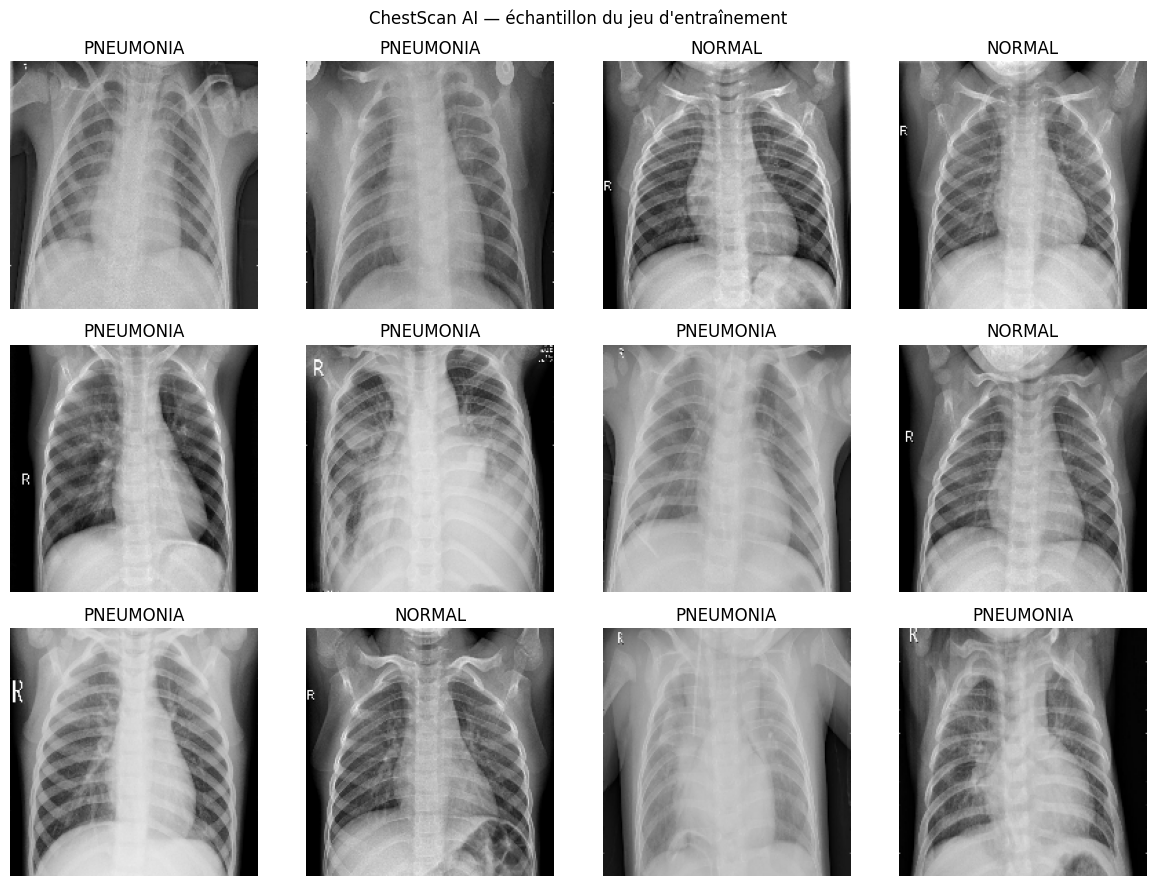

In [32]:
images_batch, labels_batch = next(iter(train_ds))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, image, label in zip(axes.flat, images_batch[:12], labels_batch[:12]):
    ax.imshow(tf.cast(tf.clip_by_value(image, 0, 255), tf.uint8).numpy())
    ax.set_title(CLASS_NAMES[int(label.numpy())])
    ax.axis("off")

plt.suptitle("ChestScan AI — échantillon du jeu d'entraînement")
plt.tight_layout()
plt.show()


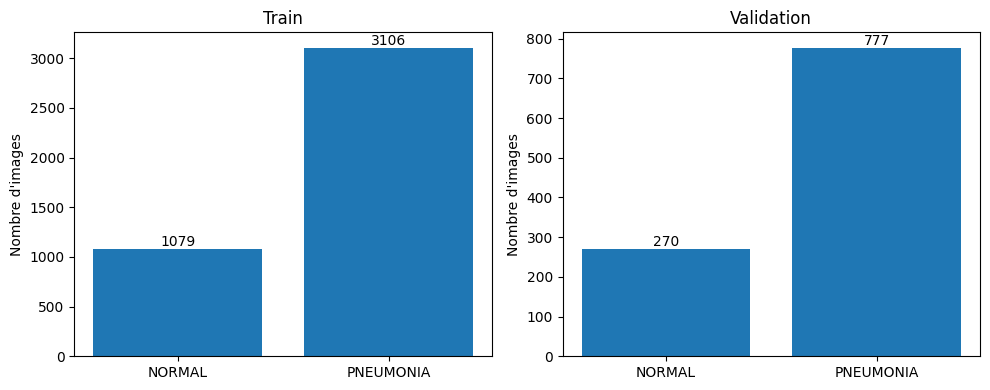

In [33]:

import matplotlib.pyplot as plt
from collections import Counter

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, counts, title in [
    (axes[0], train_counts, "Train"),
    (axes[1], val_counts, "Validation")
]:
    values = [counts[0], counts[1]]

    ax.bar(CLASS_NAMES, values)
    ax.set_title(title)
    ax.set_ylabel("Nombre d'images")

    for i, value in enumerate(values):
        ax.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()


## 6. Définition des modèles

Cette section ne lance aucun entraînement. Elle définit les architectures uniquement.

- `CNN_v2` : CNN construit depuis zéro.
- `MobileNetV2` : transfert d'apprentissage, puis fine-tuning optionnel.

Les deux modèles attendent des images RGB `180×180` avec des pixels entre `0` et `255`. Pour MobileNetV2, le redimensionnement à 224 et le preprocessing sont intégrés au modèle.


In [34]:

def build_cnn_v1():
    augmentation = keras.Sequential([
        layers.RandomRotation(0.03),
        layers.RandomTranslation(0.04, 0.04),
        layers.RandomZoom(0.08),
    ], name="data_augmentation")

    inputs = keras.Input(
        shape=(180, 180, 3),
        name="xray_input"
    )

    x = augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    # Bloc 1
    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    # Bloc 2
    x = layers.Conv2D(
        64, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    # Bloc 3
    x = layers.Conv2D(
        128, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    # Classification
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(1e-4)
    )(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="pneumonia_probability"
    )(x)

    model = keras.Model(inputs, outputs, name="chestscan_cnn_v1")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    return model


def build_mobilenet_v2():
    augmentation = keras.Sequential([
        layers.RandomRotation(0.03),
        layers.RandomTranslation(0.04, 0.04),
        layers.RandomZoom(0.08),
    ], name="data_augmentation")

    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
    )
    base_model.trainable = False

    inputs = keras.Input(
        shape=(180, 180, 3),
        name="xray_input"
    )

    x = augmentation(inputs)
    x = layers.Resizing(224, 224, name="resize")(x)
    x = layers.Lambda(
        preprocess_input,
        name="mobilenet_preprocessing"
    )(x)

    # Conserver BatchNormalization en mode inference
    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="pneumonia_probability"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name="chestscan_mobilenetv2_v1"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    return model


cnn_v2 = build_cnn_v1()
mobilenet_model = build_mobilenet_v2()
cnn_v2.summary()
mobilenet_model.summary()


Model: "chestscan_cnn_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray_input (InputLayer)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_probability (Dense)   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,561 (431.88 KB)

 Trainable params: 110,113 (430.13 KB)

 Non-trainable params: 448 (1.75 KB)

Model: "chestscan_mobilenetv2_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray_input (InputLayer)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize (Resizing)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_probability (Dense)   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Entraînement 


In [35]:
def make_callbacks(model_name):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=f"artifacts/models/{model_name}.keras",
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
            verbose=1,
        ),
    ]

##### Entraînement CNN_V1

In [36]:
cnn_v1 = build_cnn_v1()

history_cnn_v1 = cnn_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=make_callbacks("chestscan_cnn_v1_best"),
)

Epoch 1/25


I0000 00:00:1793034888.969186  109310 cuda_dnn.cc:529] Loaded cuDNN version 90300


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7603 - auc: 0.7466 - loss: 0.5088 - precision: 0.8006 - recall: 0.9001
Epoch 1: val_auc improved from -inf to 0.57616, saving model to artifacts/models/chestscan_cnn_v1_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.7606 - auc: 0.7474 - loss: 0.5081 - precision: 0.8009 - recall: 0.9002 - val_accuracy: 0.7421 - val_auc: 0.5762 - val_loss: 0.7286 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/25
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8746 - auc: 0.9347 - loss: 0.3036 - precision: 0.9108 - recall: 0.9221
Epoch 2: val_auc improved from 0.57616 to 0.69045, saving model to artifacts/models/chestscan_cnn_v1_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - accuracy: 0.8745 - auc: 0.9346 - loss: 0.3037 - precision: 0.9107 - recall: 0.9220 - val_accuracy: 0.7421 - val_auc: 0.6905 - val_loss: 1.0607 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 1.00

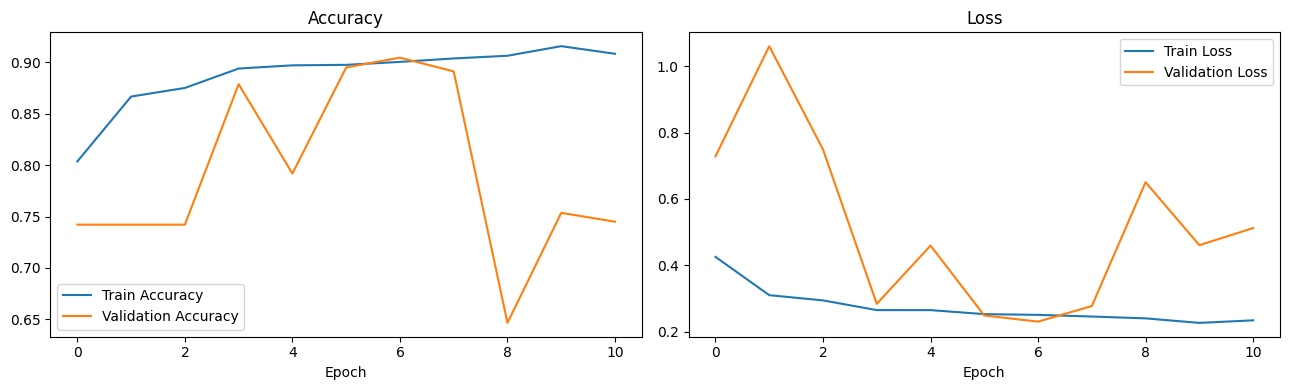

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_cnn_v1.history["accuracy"], label="Train Accuracy")
axes[0].plot(history_cnn_v1.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_cnn_v1.history["loss"], label="Train Loss")
axes[1].plot(history_cnn_v1.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

##### Entraînement TRANSFER LEARNING MOBILENETV2 

In [38]:
mobilenet_model = build_mobilenet_v2()
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=make_callbacks("chestscan_mobilenetv2_v1_best"),
)


Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8630 - auc: 0.8887 - loss: 0.3278 - precision: 0.8946 - recall: 0.9261
Epoch 1: val_auc improved from -inf to 0.98996, saving model to artifacts/models/chestscan_mobilenetv2_v1_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.8634 - auc: 0.8893 - loss: 0.3269 - precision: 0.8949 - recall: 0.9264 - val_accuracy: 0.9522 - val_auc: 0.9900 - val_loss: 0.1264 - val_precision: 0.9764 - val_recall: 0.9588 - learning_rate: 0.0010
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9532 - auc: 0.9887 - loss: 0.1193 - precision: 0.9659 - recall: 0.9709
Epoch 2: val_auc improved from 0.98996 to 0.99203, saving model to artifacts/models/chestscan_mobilenetv2_v1_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.9532 - auc: 0.9887 - loss: 0.1193 - precision: 0.9659 - recall: 0.9709 - val_accuracy: 0.9656 - val_auc: 0.9920 - val_loss: 0.0969 - val_precision: 0.9805 - val_recall: 0.973

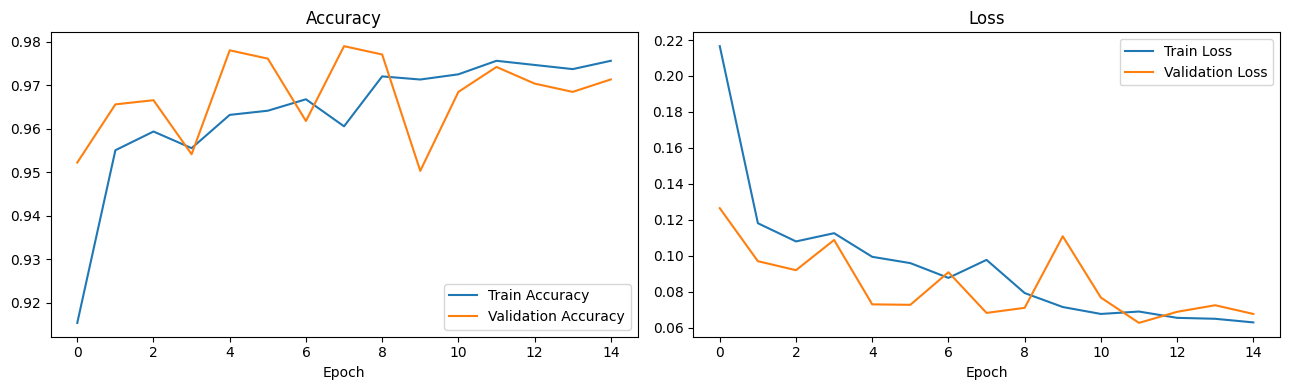

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(mobilenet_history.history["accuracy"], label="Train Accuracy")
axes[0].plot(mobilenet_history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(mobilenet_history.history["loss"], label="Train Loss")
axes[1].plot(mobilenet_history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### Entraînement FINE-TUNING MOBILENETV2 (optionnel, après transfer learning)

In [40]:
base_model = next(
    layer for layer in mobilenet_model.layers
    if isinstance(layer, keras.Model)
    and "mobilenetv2" in layer.name.lower()
)
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = not isinstance(
        layer, keras.layers.BatchNormalization
    )
mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
finetune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=make_callbacks("chestscan_mobilenetv2_v1_finetuned"),
)

Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9733 - auc: 0.9958 - loss: 0.0702 - precision: 0.9831 - recall: 0.9804
Epoch 1: val_auc improved from -inf to 0.99542, saving model to artifacts/models/chestscan_mobilenetv2_v1_finetuned.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.9733 - auc: 0.9958 - loss: 0.0702 - precision: 0.9831 - recall: 0.9804 - val_accuracy: 0.9761 - val_auc: 0.9954 - val_loss: 0.0637 - val_precision: 0.9883 - val_recall: 0.9794 - learning_rate: 1.0000e-05
Epoch 2/8
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.9737 - auc: 0.9966 - loss: 0.0666 - precision: 0.9823 - recall: 0.9823
Epoch 2: val_auc improved from 0.99542 to 0.99724, saving model to artifacts/models/chestscan_mobilenetv2_v1_finetuned.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.9738 - auc: 0.9966 - loss: 0.0665 - precision: 0.9823 - recall: 0.9823 - val_accuracy: 0.9733 - val_auc: 0.9972 - val_loss: 0.0638 - val_precision: 0.9908 - val_r

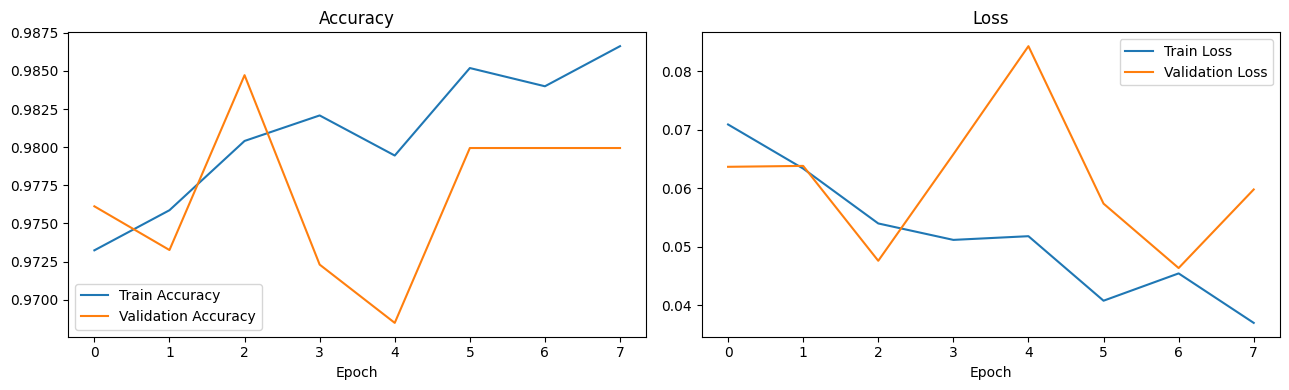

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(finetune_history.history["accuracy"], label="Train Accuracy")
axes[0].plot(finetune_history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(finetune_history.history["loss"], label="Train Loss")
axes[1].plot(finetune_history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Évaluation finale sur Test

Toutes les métriques sont calculées sur les mêmes images et dans le même ordre. Le seuil de référence est `0.50`. Ne choisis pas un seuil à partir des résultats du jeu de test.


In [42]:

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# ============================================================
# 1. Préparer le dataset de test
# ============================================================

BATCH_SIZE_EVAL = 1

test_ds_eval = test_ds.unbatch().batch(BATCH_SIZE_EVAL)

N_TEST = len(test_paths)

print("Dataset de test prêt.")
print("Nombre d'images :", N_TEST)


# ============================================================
# 2. Définir les modèles à évaluer
# ============================================================

loaded_models = {
    "CNN_v1": cnn_v1,
    "MobileNetV2_FineTuned": mobilenet_model,
}


# ============================================================
# 3. Récupérer les vrais labels
# ============================================================

def collect_true_labels(dataset):
    return np.concatenate([
        labels.numpy().reshape(-1)
        for _, labels in dataset
    ]).astype(int)


y_true = collect_true_labels(test_ds_eval)

if len(y_true) != N_TEST:
    raise ValueError(
        f"Nombre de labels ({len(y_true)}) différent "
        f"du nombre d'images ({N_TEST})."
    )

print("Labels récupérés :", len(y_true))


# ============================================================
# 4. Évaluer un modèle
# ============================================================

def evaluate_model(model, dataset, y_true, threshold=0.5):

    probabilities = model.predict(
        dataset,
        verbose=1,
    )

    probabilities = np.asarray(probabilities)

    # Vérifier la sortie du modèle
    if probabilities.ndim == 2 and probabilities.shape[1] == 1:
        probabilities = probabilities[:, 0]
    elif probabilities.ndim == 1:
        pass
    else:
        raise ValueError(
            "Le modèle doit retourner un seul score par image. "
            f"Forme obtenue : {probabilities.shape}"
        )

    probabilities = probabilities.reshape(-1)

    if len(probabilities) != len(y_true):
        raise ValueError(
            f"Nombre de prédictions : {len(probabilities)} ; "
            f"nombre de labels : {len(y_true)}."
        )

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Les prédictions contiennent NaN ou Inf.")

    if np.any(probabilities < 0) or np.any(probabilities > 1):
        raise ValueError(
            "Les sorties ne semblent pas être des probabilités "
            "comprises entre 0 et 1."
        )

    # Seuil de classification
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    metrics = {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Specificity": (
            tn / (tn + fp) if (tn + fp) > 0 else 0.0
        ),
        "ROC-AUC": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2
            else float("nan")
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

    return {
        "probabilities": probabilities,
        "predictions": predictions,
        "metrics": metrics,
    }


# ============================================================
# 5. Vérifier les modèles avant l'évaluation
# ============================================================

for model_name, model in loaded_models.items():
    if model is None:
        raise ValueError(
            f"Le modèle {model_name} n'est pas chargé."
        )

    print(
        f"{model_name} : modèle prêt | "
        f"sortie = {model.output_shape}"
    )

print("\nConfiguration d'évaluation prête.")


Dataset de test prêt.
Nombre d'images : 624
Labels récupérés : 624
CNN_v1 : modèle prêt | sortie = (None, 1)
MobileNetV2_FineTuned : modèle prêt | sortie = (None, 1)

Configuration d'évaluation prête.


2026-10-26 17:19:31.793090: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [43]:

import gc
import pandas as pd
from collections import Counter
from IPython.display import display

# ============================================================
# 1. Vérifier la configuration
# ============================================================

if not loaded_models:
    raise ValueError("Aucun modèle disponible dans loaded_models.")

if len(y_test := collect_true_labels(test_ds_eval)) == 0:
    raise ValueError("Le dataset de test est vide.")

THRESHOLD = 0.6

test_results = {}
summary_rows = []

print("Images Test :", len(y_test))
print("Distribution des labels :", dict(Counter(y_test)))
print("Seuil de classification :", THRESHOLD)


# ============================================================
# 2. Évaluer les modèles
# ============================================================

for model_name, model in loaded_models.items():

    print(f"\n{'=' * 50}")
    print(f"Évaluation : {model_name}")
    print(f"{'=' * 50}")

    result = evaluate_model(
        model=model,
        dataset=test_ds_eval,
        y_true=y_test,
        threshold=THRESHOLD,
    )

    test_results[model_name] = result

    summary_rows.append({
        "Model": model_name,
        "Threshold": THRESHOLD,
        **result["metrics"],
    })

    print(
        f"Accuracy : {result['metrics']['Accuracy']:.4f} | "
        f"Recall : {result['metrics']['Recall']:.4f} | "
        f"F1-score : {result['metrics']['F1-score']:.4f} | "
        f"ROC-AUC : {result['metrics']['ROC-AUC']:.4f}"
    )

    gc.collect()


# ============================================================
# 3. Comparer les résultats
# ============================================================

test_summary = pd.DataFrame(summary_rows)

if not test_summary.empty:

    test_summary = test_summary.sort_values(
        by="F1-score",
        ascending=False,
    ).reset_index(drop=True)

    print("\nComparaison des modèles sur le test :")

    display(test_summary.round(4))

    # Sauvegarder le rapport
    REPORTS_DIR.mkdir(parents=True, exist_ok=True)

    report_path = REPORTS_DIR / "test_model_comparison.csv"

    test_summary.to_csv(
        report_path,
        index=False,
    )

    print("\nRapport sauvegardé :", report_path)

    print("\nMeilleur modèle selon le F1-score :")
    print(test_summary.iloc[0]["Model"])

else:
    raise ValueError("Aucun résultat n'a été généré.")


2026-10-26 17:19:32.779995: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Images Test : 624
Distribution des labels : {np.int64(0): 234, np.int64(1): 390}
Seuil de classification : 0.6

Évaluation : CNN_v1
624/624 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


/venv/main/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Accuracy : 0.6955 | Recall : 0.9718 | F1-score : 0.7996 | ROC-AUC : 0.8988

Évaluation : MobileNetV2_FineTuned
624/624 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step


/venv/main/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
2026-10-26 17:19:41.679338: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Accuracy : 0.8173 | Recall : 0.9974 | F1-score : 0.8722 | ROC-AUC : 0.9677

Comparaison des modèles sur le test :


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,TN,FP,FN,TP
0,MobileNetV2_FineTuned,0.6,0.8173,0.7749,0.9974,0.8722,0.5171,0.9677,121,113,1,389
1,CNN_v1,0.6,0.6955,0.6792,0.9718,0.7996,0.2350,0.8988,55,179,11,379



Rapport sauvegardé : /workspace/chestscan-ai-cnn/artifacts/reports/test_model_comparison.csv

Meilleur modèle selon le F1-score :
MobileNetV2_FineTuned


## 9. Matrice de confusion et rapport détaillé



In [44]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# ============================================================
# 1. Récupérer les labels réels de validation
# ============================================================

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in val_ds
]).astype(int)

# ============================================================
# 2. Prédire les probabilités
# ============================================================

y_prob = mobilenet_model.predict(
    val_ds,
    verbose=1,
).reshape(-1)

if len(y_true) != len(y_prob):
    raise ValueError(
        f"Nombre de labels ({len(y_true)}) différent "
        f"du nombre de prédictions ({len(y_prob)})."
    )

if not np.all(np.isfinite(y_prob)):
    raise ValueError("Les probabilités contiennent NaN ou Inf.")

if np.any(y_prob < 0) or np.any(y_prob > 1):
    raise ValueError(
        "Les sorties du modèle ne sont pas des probabilités "
        "comprises entre 0 et 1."
    )

print("Images de validation :", len(y_true))
print("Distribution réelle :", {
    "NORMAL": int(np.sum(y_true == 0)),
    "PNEUMONIA": int(np.sum(y_true == 1)),
})

# ============================================================
# 3. Comparer les seuils
# ============================================================

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    recall_pneumonia = tp / (tp + fn) if (tp + fn) else 0.0

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall_PNEUMONIA": recall_pneumonia,
        "Recall_NORMAL": specificity,
        "Specificity": specificity,
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    })

threshold_summary = pd.DataFrame(results)

display(
    threshold_summary.round(4)
)

# ============================================================
# 4. Sauvegarder le rapport
# ============================================================

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

threshold_path = REPORTS_DIR / "mobilenet_threshold_comparison.csv"

threshold_summary.to_csv(
    threshold_path,
    index=False,
)

print("Rapport sauvegardé :", threshold_path)


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step
Images de validation : 1047
Distribution réelle : {'NORMAL': 270, 'PNEUMONIA': 777}


,Threshold,Accuracy,Precision,Recall_PNEUMONIA,Recall_NORMAL,Specificity,F1-score,TN,FP,FN,TP
0,0.3,0.9809,0.9797,0.9949,0.9407,0.9407,0.9872,254,16,4,773
1,0.4,0.9799,0.9821,0.9910,0.9481,0.9481,0.9865,256,14,7,770
2,0.5,0.9799,0.9859,0.9871,0.9593,0.9593,0.9865,259,11,10,767
3,0.6,0.9828,0.9897,0.9871,0.9704,0.9704,0.9884,262,8,10,767
4,0.7,0.9819,0.9922,0.9833,0.9778,0.9778,0.9877,264,6,13,764


Rapport sauvegardé : /workspace/chestscan-ai-cnn/artifacts/reports/mobilenet_threshold_comparison.csv


In [45]:
print("Nombre de labels :", len(y_true))
print("Nombre de prédictions :", len(y_prob))
print("Distribution réelle :", np.unique(y_true, return_counts=True))

Nombre de labels : 1047
Nombre de prédictions : 1047
Distribution réelle : (array([0, 1]), array([270, 777]))


In [46]:

from sklearn.metrics import confusion_matrix, classification_report

# Vérifier que les résultats existent
if not test_results:
    raise ValueError(
        "Aucun résultat disponible. Exécute d'abord l'évaluation des modèles."
    )

for model_name, result in test_results.items():

    y_pred = np.asarray(result["predictions"]).reshape(-1)

    if len(y_pred) != len(y_test):
        raise ValueError(
            f"{model_name} : {len(y_pred)} prédictions "
            f"pour {len(y_test)} labels réels."
        )

    print(f"\n{'=' * 55}")
    print(f"MODÈLE : {model_name}")
    print(f"{'=' * 55}")

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1],
    )

    print("\nMatrice de confusion [[TN, FP], [FN, TP]] :")
    print(cm)

    print("\nRapport de classification :")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0,
        )
    )

    tn, fp, fn, tp = cm.ravel()

    print("Résumé :")
    print(f"TN — NORMAL correctement identifié : {tn}")
    print(f"FP — NORMAL prédit PNEUMONIA      : {fp}")
    print(f"FN — PNEUMONIA prédit NORMAL      : {fn}")
    print(f"TP — PNEUMONIA correctement identifié : {tp}")



MODÈLE : CNN_v1

Matrice de confusion [[TN, FP], [FN, TP]] :
[[ 55 179]
 [ 11 379]]

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL     0.8333    0.2350    0.3667       234
   PNEUMONIA     0.6792    0.9718    0.7996       390

    accuracy                         0.6955       624
   macro avg     0.7563    0.6034    0.5831       624
weighted avg     0.7370    0.6955    0.6372       624

Résumé :
TN — NORMAL correctement identifié : 55
FP — NORMAL prédit PNEUMONIA      : 179
FN — PNEUMONIA prédit NORMAL      : 11
TP — PNEUMONIA correctement identifié : 379

MODÈLE : MobileNetV2_FineTuned

Matrice de confusion [[TN, FP], [FN, TP]] :
[[121 113]
 [  1 389]]

Rapport de classification :
              precision    recall  f1-score   support

      NORMAL     0.9918    0.5171    0.6798       234
   PNEUMONIA     0.7749    0.9974    0.8722       390

    accuracy                         0.8173       624
   macro avg     0.8834    0.7573    0.7

## 10. Analyse des faux positifs

Cette cellule affiche des images `NORMAL` que le modèle a classées `PNEUMONIA`. Elle nécessite un modèle évalué dans la cellule précédente.


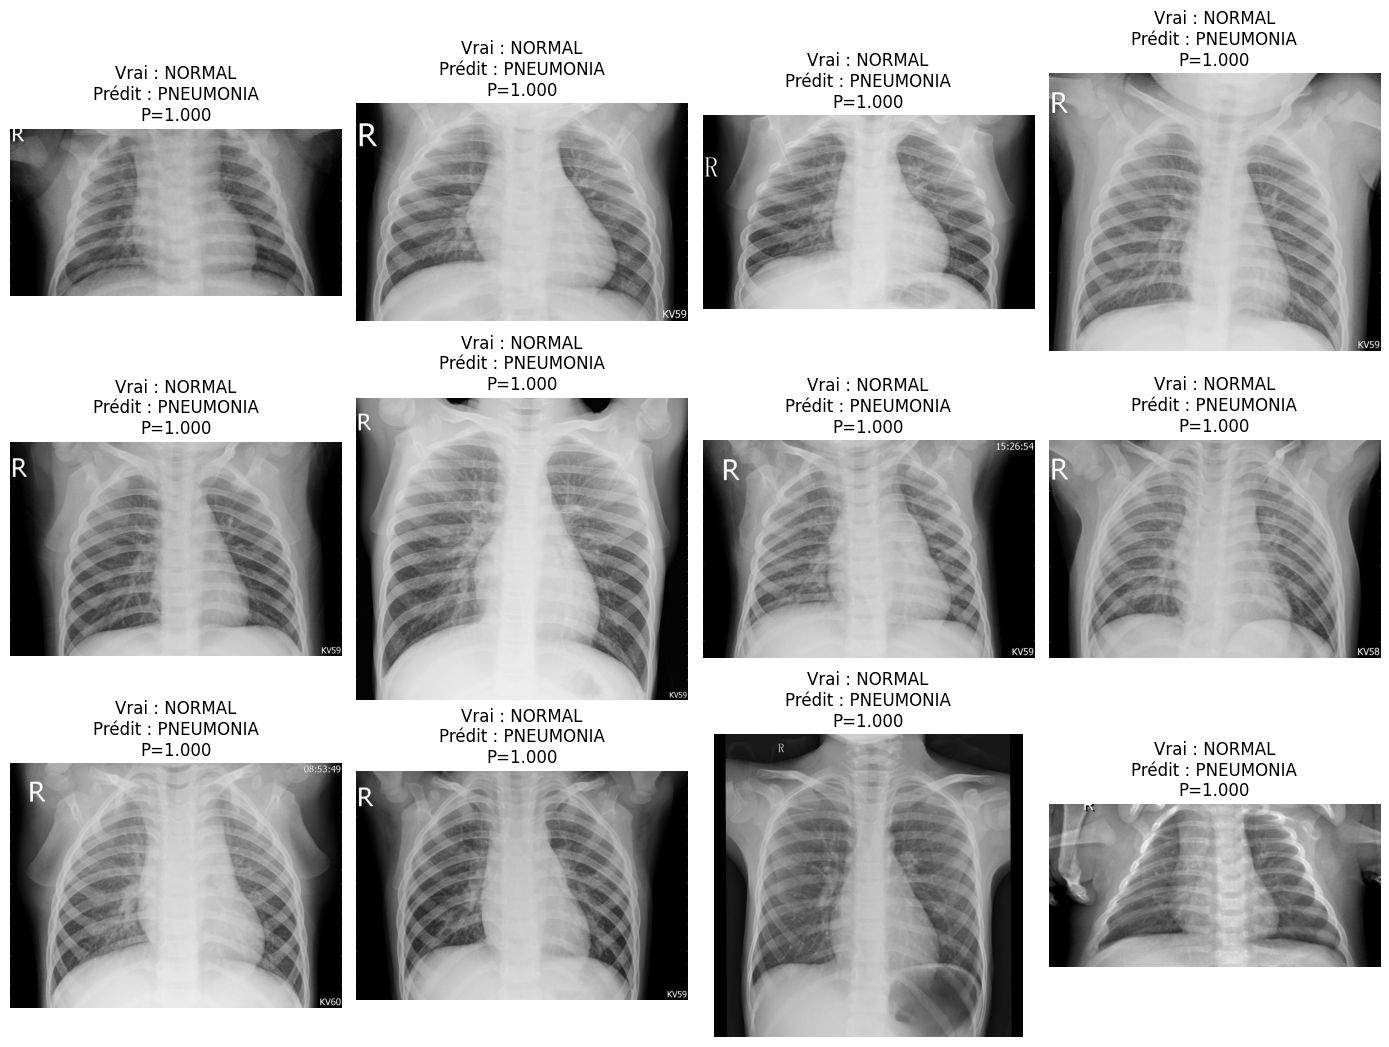

In [47]:
MODEL_TO_INSPECT = "MobileNetV2_FineTuned"
THRESHOLD = 0.5
N_IMAGES = 12

if MODEL_TO_INSPECT not in test_results:
    print(f"Modèle non disponible : {MODEL_TO_INSPECT}. Choisis un nom dans {list(test_results)}")
else:
    probabilities = test_results[MODEL_TO_INSPECT]["probabilities"]
    predictions = (probabilities >= THRESHOLD).astype(int)
    false_positives = np.where((y_test == 0) & (predictions == 1))[0]
    selected = false_positives[
        np.argsort(probabilities[false_positives])[::-1][:N_IMAGES]
    ]

    if len(selected) == 0:
        print("Aucun faux positif avec ce seuil.")
    else:
        cols = 4
        rows = int(np.ceil(len(selected) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
        axes = np.asarray(axes).reshape(-1)

        for ax in axes:
            ax.axis("off")

        for ax, idx in zip(axes, selected):
            with Image.open(test_paths[idx]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"Vrai : NORMAL\nPrédit : PNEUMONIA\nP={probabilities[idx]:.3f}"
            )
            ax.axis("off")

        plt.tight_layout()
        plt.show()


## 11. Analyse exploratoire des seuils sur Validation

Utilise la validation pour étudier l'effet du seuil. Cette analyse ne modifie pas le modèle enregistré. Après avoir choisi une stratégie, l'évaluation finale sur Test doit rester séparée et être rapportée sans ajustements supplémentaires.


In [48]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from IPython.display import display

# ============================================================
# 1. Configuration
# ============================================================

THRESHOLDS = np.round(np.arange(0.10, 0.96, 0.05), 2)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Récupérer les vrais labels de validation
# ============================================================

y_val_true = collect_true_labels(val_ds)

validation_results = []

print("Nombre d'images de validation :", len(y_val_true))
print("Distribution des labels :", dict(Counter(y_val_true)))

# ============================================================
# 3. Évaluer les seuils de chaque modèle
# ============================================================

for model_name, model in loaded_models.items():

    print(f"\nÉvaluation : {model_name}")

    val_probabilities = model.predict(
        val_ds,
        verbose=1,
    ).reshape(-1)

    if len(val_probabilities) != len(y_val_true):
        raise ValueError(
            f"{model_name} : {len(val_probabilities)} prédictions "
            f"pour {len(y_val_true)} labels."
        )

    if not np.all(np.isfinite(val_probabilities)):
        raise ValueError(
            f"{model_name} : probabilités NaN ou Inf."
        )

    if np.any(val_probabilities < 0) or np.any(val_probabilities > 1):
        raise ValueError(
            f"{model_name} : les sorties ne sont pas des "
            "probabilités comprises entre 0 et 1."
        )

    # AUC indépendante du seuil
    auc = (
        roc_auc_score(y_val_true, val_probabilities)
        if len(np.unique(y_val_true)) == 2
        else float("nan")
    )

    for threshold in THRESHOLDS:

        val_predictions = (
            val_probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_true,
            val_predictions,
            labels=[0, 1],
        ).ravel()

        validation_results.append({
            "Model": model_name,
            "Threshold": float(threshold),
            "Accuracy": accuracy_score(
                y_val_true, val_predictions
            ),
            "Precision": precision_score(
                y_val_true, val_predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_true, val_predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val_true, val_predictions, zero_division=0
            ),
            "Specificity": (
                tn / (tn + fp) if (tn + fp) else 0.0
            ),
            "ROC-AUC": auc,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
        })

# ============================================================
# 4. Afficher les meilleurs seuils
# ============================================================

validation_thresholds_df = pd.DataFrame(validation_results)

if validation_thresholds_df.empty:
    raise ValueError("Aucun résultat de validation n'a été généré.")

for model_name in validation_thresholds_df["Model"].unique():

    model_results = validation_thresholds_df[
        validation_thresholds_df["Model"] == model_name
    ]

    print(f"\nTop 5 seuils par F1-score — {model_name}")

    display(
        model_results
        .sort_values(
            ["F1-score", "Recall"],
            ascending=[False, False],
        )
        .head(5)
        .round(4)
    )

# ============================================================
# 5. Sauvegarder les résultats
# ============================================================

report_path = REPORTS_DIR / "validation_threshold_results.csv"

validation_thresholds_df.to_csv(
    report_path,
    index=False,
)

print("\nRapport sauvegardé :", report_path)


Nombre d'images de validation : 1047
Distribution des labels : {np.int64(1): 777, np.int64(0): 270}

Évaluation : CNN_v1
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step

Évaluation : MobileNetV2_FineTuned
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step

Top 5 seuils par F1-score — CNN_v1


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,TN,FP,FN,TP
10,CNN_v1,0.60,0.9245,0.9429,0.9562,0.9495,0.8333,0.974,225,45,34,743
11,CNN_v1,0.65,0.9255,0.9569,0.9421,0.9494,0.8778,0.974,237,33,45,732
12,CNN_v1,0.70,0.9245,0.9653,0.9318,0.9483,0.9037,0.974,244,26,53,724
13,CNN_v1,0.75,0.9207,0.9753,0.9163,0.9449,0.9333,0.974,252,18,65,712
9,CNN_v1,0.55,0.9150,0.9268,0.9614,0.9438,0.7815,0.974,211,59,30,747



Top 5 seuils par F1-score — MobileNetV2_FineTuned


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,TN,FP,FN,TP
28,MobileNetV2_FineTuned,0.60,0.9828,0.9897,0.9871,0.9884,0.9704,0.9983,262,8,10,767
29,MobileNetV2_FineTuned,0.65,0.9828,0.9922,0.9846,0.9884,0.9778,0.9983,264,6,12,765
25,MobileNetV2_FineTuned,0.45,0.9819,0.9847,0.9910,0.9878,0.9556,0.9983,258,12,7,770
27,MobileNetV2_FineTuned,0.55,0.9819,0.9884,0.9871,0.9878,0.9667,0.9983,261,9,10,767
30,MobileNetV2_FineTuned,0.70,0.9819,0.9922,0.9833,0.9877,0.9778,0.9983,264,6,13,764



Rapport sauvegardé : /workspace/chestscan-ai-cnn/artifacts/reports/validation_threshold_results.csv


## 12. Sauvegarder explicitement le modèle retenu — action manuelle

Ne lance cette cellule qu'après avoir choisi le modèle à conserver. Elle copie le modèle sélectionné vers `artifacts/models/model.keras`, qui est le chemin attendu par la configuration Docker/API actuelle. Vérifie d'abord que le modèle choisi est bien celui que tu souhaites déployer.


In [49]:

from pathlib import Path
import gc

# ============================================================
# 1. Configuration
# ============================================================

MODELS_DIR = Path("/workspace/chestscan-ai-cnn/artifacts/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Sauvegarder chaque modèle séparément
# ============================================================

for model_name, model in loaded_models.items():

    if model is None:
        print(f"Modèle ignoré : {model_name} (None)")
        continue

    # Nom de fichier indépendant pour chaque modèle
    model_path = MODELS_DIR / f"{model_name}.keras"

    print(f"\nSauvegarde de : {model_name}")
    model.save(model_path)

    size_mb = model_path.stat().st_size / (1024 * 1024)

    print("Chemin :", model_path)
    print(f"Taille : {size_mb:.2f} Mo")

    gc.collect()

print("\nSauvegarde des modèles terminée.")



Sauvegarde de : CNN_v1
Chemin : /workspace/chestscan-ai-cnn/artifacts/models/CNN_v1.keras
Taille : 1.35 Mo

Sauvegarde de : MobileNetV2_FineTuned
Chemin : /workspace/chestscan-ai-cnn/artifacts/models/MobileNetV2_FineTuned.keras
Taille : 22.61 Mo

Sauvegarde des modèles terminée.


In [50]:

# Modèle choisi pour le déploiement
MODEL_TO_EXPORT = "MobileNetV2_FineTuned"

if MODEL_TO_EXPORT not in loaded_models:
    raise ValueError(
        f"Modèle absent : {MODEL_TO_EXPORT}"
    )

export_path = MODELS_DIR / "model.keras"

# Sauvegarde du modèle sélectionné pour Docker/API
loaded_models[MODEL_TO_EXPORT].save(export_path)

print("Modèle sélectionné :", MODEL_TO_EXPORT)
print("Modèle exporté :", export_path.resolve())
print(
    "Taille (Mo) :",
    round(export_path.stat().st_size / (1024 * 1024), 2),
)


Modèle sélectionné : MobileNetV2_FineTuned
Modèle exporté : /workspace/chestscan-ai-cnn/artifacts/models/model.keras
Taille (Mo) : 22.61


## Règles de maintenance

- Ne pas mélanger les données de `val` et `test`.
- Ne pas appliquer `preprocess_input` une deuxième fois en dehors du modèle MobileNetV2.
- Garder les chemins dans `PROJECT_ROOT`, `MODELS_DIR` et `REPORTS_DIR`.
- Ne pas entraîner automatiquement lorsqu'on veut uniquement évaluer.
- Avant de remplacer `model.keras`, vérifier les métriques du modèle sélectionné.
- Ce prototype est pédagogique et ne doit pas être utilisé pour un diagnostic médical.


In [51]:

import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import tensorflow as tf
import sklearn
import PIL

print("=== ENVIRONNEMENT ===")
print("Date UTC :", datetime.now(timezone.utc).isoformat())
print("Python :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Pillow :", PIL.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

# Détecter les modèles déjà présents dans le notebook
model_candidates = [
    "cnn_v2",
    "mobilenet_model",
    "CNN_v2",
    "MobileNetV2_FineTuned",
    "mobilenet_v2_model",
]

models_found = {}

for variable_name in model_candidates:
    obj = globals().get(variable_name)

    if isinstance(obj, tf.keras.Model):
        models_found[variable_name] = obj

        print(f"\n=== MODÈLE : {variable_name} ===")
        print("Nom :", obj.name)
        print("Paramètres totaux :", obj.count_params())
        print(
            "Paramètres entraînables :",
            sum(
                int(np.prod(w.shape))
                for w in obj.trainable_weights
            )
        )
        print("Nombre de couches :", len(obj.layers))
        print("Entrée :", obj.input_shape)
        print("Sortie :", obj.output_shape)

if not models_found:
    print(
        "\nAucun modèle trouvé sous les noms connus. "
        "Ne recrée pas les modèles : vérifions leurs noms "
        "dans le notebook."
    )


=== ENVIRONNEMENT ===
Date UTC : 2026-10-26T17:19:55.271183+00:00
Python : 3.10.12
TensorFlow : 2.19.0
NumPy : 2.1.3
Scikit-learn : 1.7.2
Pillow : 12.3.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

=== MODÈLE : cnn_v2 ===
Nom : chestscan_cnn_v1
Paramètres totaux : 110561
Paramètres entraînables : 110113
Nombre de couches : 19
Entrée : (None, 180, 180, 3)
Sortie : (None, 1)

=== MODÈLE : mobilenet_model ===
Nom : chestscan_mobilenetv2_v1
Paramètres totaux : 2422081
Paramètres entraînables : 1674817
Nombre de couches : 9
Entrée : (None, 180, 180, 3)
Sortie : (None, 1)


In [52]:
from pathlib import Path
import gc
import json

import mlflow
import mlflow.keras
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

# --------------------------------------------------
# 1. Configuration MLflow
# --------------------------------------------------

PROJECT_DIR = Path("/workspace/chestscan-ai-cnn")
MODELS_DIR = PROJECT_DIR / "artifacts" / "models"
REPORTS_DIR = PROJECT_DIR / "artifacts" / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_experiment("ChestScan-AI-Model-Comparison")

# Utilise le seuil choisi sur la validation.
# Remplace 0.60 si ton seuil validé est différent.
THRESHOLD = 0.60

# --------------------------------------------------
# 2. Récupérer les vraies étiquettes du test
# --------------------------------------------------

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

results = []

# --------------------------------------------------
# 3. Évaluer et enregistrer chaque modèle
# --------------------------------------------------

for model_name, model in loaded_models.items():

    if model is None:
        print(f"Modèle ignoré : {model_name}")
        continue

    print(f"\nÉvaluation de {model_name}...")

    with mlflow.start_run(run_name=model_name):

        # Prédictions : classe positive = PNEUMONIA (label 1)
        y_prob = model.predict(test_ds, verbose=0).reshape(-1)

        if len(y_prob) != len(y_true):
            raise ValueError(
                f"{model_name}: nombre de prédictions différent "
                "du nombre de labels."
            )

        y_pred = (y_prob >= THRESHOLD).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        metrics = {
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1_score": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "true_negatives": int(tn),
            "false_positives": int(fp),
            "false_negatives": int(fn),
            "true_positives": int(tp),
        }

        if len(np.unique(y_true)) == 2:
            metrics["roc_auc"] = roc_auc_score(y_true, y_prob)

        # Paramètres de l'expérience
        mlflow.log_params({
            "model_name": model_name,
            "image_height": 180,
            "image_width": 180,
            "batch_size": 32,
            "threshold": THRESHOLD,
            "evaluation_split": "test",
            "positive_class": "PNEUMONIA",
        })

        # Métriques numériques visibles dans MLflow
        mlflow.log_metrics(metrics)

        # Rapport de classification
        report = classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["NORMAL", "PNEUMONIA"],
            output_dict=True,
            zero_division=0,
        )

        report_path = REPORTS_DIR / f"{model_name}_test_report.json"
        with open(report_path, "w", encoding="utf-8") as f:
            json.dump(report, f, indent=4)

        mlflow.log_artifact(str(report_path))

        # Matrice de confusion sous forme JSON
        cm_path = REPORTS_DIR / f"{model_name}_confusion_matrix.json"
        with open(cm_path, "w", encoding="utf-8") as f:
            json.dump({
                "labels": ["NORMAL", "PNEUMONIA"],
                "matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
            }, f, indent=4)

        mlflow.log_artifact(str(cm_path))

        # Sauvegarde indépendante de chaque modèle
        model_path = MODELS_DIR / f"{model_name}.keras"
        model.save(model_path)

        # Enregistrer aussi le modèle comme artefact du run
        mlflow.log_artifact(str(model_path), artifact_path="model_file")

        results.append({
            "model": model_name,
            **metrics,
        })

        print("Métriques :", metrics)
        print("Modèle sauvegardé :", model_path)

        gc.collect()

print("\nEnregistrement des expériences terminé.")

2026/10/26 17:19:56 INFO mlflow.tracking.fluent: Experiment with name 'ChestScan-AI-Model-Comparison' does not exist. Creating a new experiment.



Évaluation de CNN_v1...
Métriques : {'accuracy': 0.6955128205128205, 'precision': 0.6792114695340502, 'recall': 0.9717948717948718, 'f1_score': 0.79957805907173, 'specificity': np.float64(0.23504273504273504), 'true_negatives': 55, 'false_positives': 179, 'false_negatives': 11, 'true_positives': 379, 'roc_auc': 0.8987727372342758}
Modèle sauvegardé : /workspace/chestscan-ai-cnn/artifacts/models/CNN_v1.keras

Évaluation de MobileNetV2_FineTuned...
Métriques : {'accuracy': 0.8173076923076923, 'precision': 0.7749003984063745, 'recall': 0.9974358974358974, 'f1_score': 0.8721973094170403, 'specificity': np.float64(0.5170940170940171), 'true_negatives': 121, 'false_positives': 113, 'false_negatives': 1, 'true_positives': 389, 'roc_auc': 0.9674665790050405}
Modèle sauvegardé : /workspace/chestscan-ai-cnn/artifacts/models/MobileNetV2_FineTuned.keras

Enregistrement des expériences terminé.
